In [1]:
import numpy as np 
import matplotlib.pyplot as plt 

AND: epochs = 6 w = [1.  0.5] b = -1.0
AND: mistakes per epoch = [1, 3, 3, 2, 1, 0]
AND: final predictions  = [0 0 0 1]
XOR: epochs = 20 w = [-0.5  0. ] b = 0.5
XOR: mistakes per epoch = [2, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
XOR: final predictions  = [1 1 0 0]


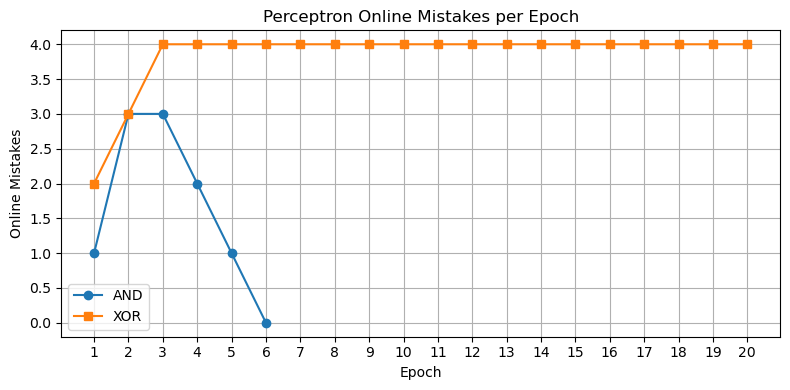


Final wrong predictions on AND: 0
Final wrong predictions on XOR: 2
Task 1 OK


In [ ]:
import numpy as np 
import matplotlib.pyplot as plt 

X = np.array([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
])

y_and = np.array([0, 0, 0, 1])
y_xor = np.array([0, 1, 1, 0])


def predict(X, w, b):
  return (X @ w + b > 0).astype(int)


def train_perceptron(X, y, eta=0.5, max_epochs=20):
  w = np.zeros(2)
  b = 0.0

  mistakes_per_epoch = []

  for epoch in range(max_epochs):
    mistakes = 0

    for i in range(len(X)):
      x_i = X[i]
      y_i = y[i]

      z_i = (x_i @ w) + b
      y_hat_i = 1 if z_i > 0 else 0

      error_i = y_i - y_hat_i

      if error_i != 0:
        mistakes += 1
        w = w + eta * error_i * x_i
        b = b + eta * error_i

    mistakes_per_epoch.append(mistakes)

    if mistakes == 0:
      break

  return w, b, mistakes_per_epoch


w_and, b_and, hist_and = train_perceptron(X, y_and)
w_xor, b_xor, hist_xor = train_perceptron(X, y_xor)

print("AND: epochs =", len(hist_and), "w =", w_and, "b =", b_and)
print("AND: mistakes per epoch =", hist_and)
print("AND: final predictions  =", predict(X, w_and, b_and))

print("XOR: epochs =", len(hist_xor), "w =", w_xor, "b =", b_xor)
print("XOR: mistakes per epoch =", hist_xor)
print("XOR: final predictions  =", predict(X, w_xor, b_xor))

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(hist_and) + 1), hist_and, "o-", label="AND")
plt.plot(range(1, len(hist_xor) + 1), hist_xor, "s-", label="XOR")
plt.xlabel("Epoch")
plt.ylabel("Online Mistakes")
plt.title("Perceptron Online Mistakes per Epoch")
plt.xticks(range(1, max(len(hist_and), len(hist_xor)) + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

final_errors_and = np.sum(predict(X, w_and, b_and) != y_and)
final_errors_xor = np.sum(predict(X, w_xor, b_xor) != y_xor)

print(f"\nFinal wrong predictions on AND: {final_errors_and}")
print(f"Final wrong predictions on XOR: {final_errors_xor}")

assert np.all(predict(X, w_and, b_and) == y_and)

print("Task 1 OK")

1. Why must the parameters be reset before the XOR run?
<br>Because the weights and bias were changed during the AND training. We need a clean start with zeros to train a new model for XOR from the beginning.

2. Why does success on AND not imply success on XOR?
<br>Because AND is linearly separable (a straight line can divide the classes), but XOR is not linearly separable.

3. Why can more epochs not overcome a single perceptron’s linear-boundary limitation on XOR?
<br>Because a single perceptron can only draw a straight line. XOR needs two lines, so no matter how many epochs we run, the straight line can never separate XOR correctly.

4. Are online mistakes during an epoch always equal to the final model’s errors?
<br>No, online mistakes are counted during the training epoch while parameters are still changing. The final model's errors are checked at the very end when training is finished.